<a href="https://colab.research.google.com/github/MalezhykDaniil/ML/blob/main/%D0%9B%D0%A0_7_%D0%9C%D0%B0%D0%BB%D0%B5%D0%B6%D0%B8%D0%BA_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [ ]:
# Варіант 1. Завантаження файлу в Google Colab
# from google.colab import files
# files.upload()
# df = pd.read_csv('data.csv')
# df.head()

In [2]:
# Варіант 2. Завантаження датасету через KaggleHub
import kagglehub
import os
path = kagglehub.dataset_download('unmoved/cure-the-princess')
df = pd.read_csv(os.path.join(path, 'data.csv'))
df.head()

100%|██████████| 49.2k/49.2k [00:00<00:00, 1.40MB/s]

Extracting files...


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB


In [4]:
df.isnull().sum()

,0
Phoenix Feather,0
Unicorn Horn,0
Dragon's Blood,0
Mermaid Tears,0
Fairy Dust,0
Goblin Toes,0
Witch's Brew,0
Griffin Claw,0
Troll Hair,0
Kraken Ink,0


In [5]:
df.describe()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


Кількість спостережень (розмір вибірки): Для всіх без винятку стовпчиків значення count становить 2338.000000. Це означає, що у датасеті є 2338 рядків і пропусків (Missing Values) за цими числовими ознаками немає (кількість незпущених значень скрізь однакова).   Цільова змінна (Cured):Має мінімум 0.000000 та максимум 1.000000, що вказує на її бінарний характер (0 або 1).   Середнє значення (mean) дорівнює приблизно 0.496578, а медіана (50%) — 0.000000. Це свідчить про те, що класи у цільовій змінній збаланмовані приблизно порівну (близько 50% на 50%).   Розподіл числових ознак (інгредієнтів):Усі показники інгредієнтів (від Phoenix Feather до Chimera Fang) мають мінімальні значення рівно 1.000000.   Середні значення (mean) та медіани (50%) для більшості інгредієнтів дуже близькі між собою (наприклад, для Phoenix Feather середнє — 15.36, медіана — 14.70; для Dragon's Blood середнє — 16.11, медіана — 15.80), що говорить про симетричність або близький до нормального розподіл даних без різких перекосів.Стандартне відхилення (std) для більшості інгредієнтів коливається в межах 7–9, а максимальні значення досягають приблизно 33–44.

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [6]:
X = df.drop('Cured', axis=1)
y = df['Cured']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### 5. Баланс класів на навчальній вибірці

In [7]:
y_train.value_counts()

,count
Cured,
0,946
1,924


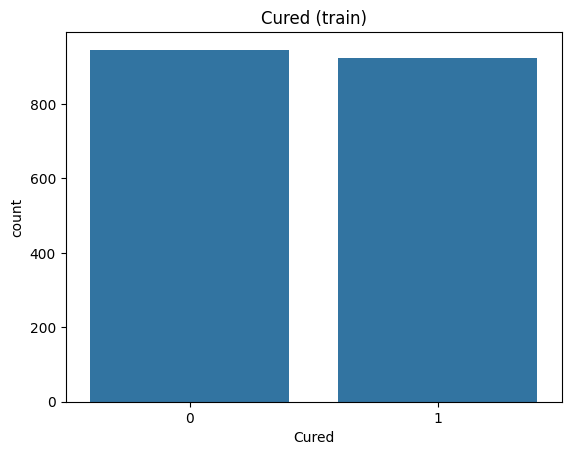

In [8]:
sns.countplot(x=y_train)
plt.title('Cured (train)')
plt.show()

класи чудово збалансовані.   Для класу 0 кількість елементів становить 946, а для класу 1 — 924. Співвідношення практично рівне (близько 50 на 50).   Чому це може вплинути на оцінку моделі?Об'єктивність метрик: Завдяки рівній кількості об'єктів обох класів такі метрики, як Accuracy (точність), Precision, Recall та ROC-AUC, будуть повністю адекватними й не спотворюватимуться. Немає ризику, що модель просто «вгадає» мажоритарний клас.Відсутність перекосу (Bias): Модель навчатиметься однаково добре розпізнавати як нульовий, так і перший класи, оскільки жоден із них не домінує у вибірці.   Відсутність потреби у додатковій обробці: Оскільки дисбалансу немає, не потрібно застосовувати трудомісткі методи ресэмплингу (наприклад, SMOTE, Oversampling чи Undersampling), що спрощує пайплайн машинного навчання та знижує ризик перенавчання.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

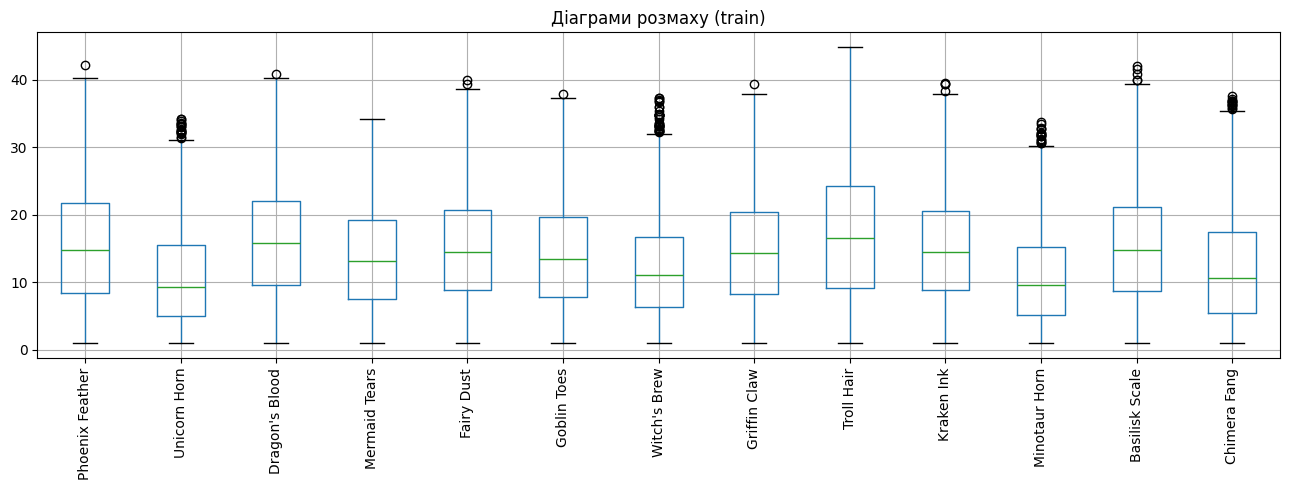

In [9]:
X_train.boxplot(figsize=(13, 5), rot=90)
plt.title('Діаграми розмаху (train)')
plt.tight_layout()
plt.show()

In [10]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1

outliers = ((X_train < q1 - 1.5 * iqr) | (X_train > q3 + 1.5 * iqr)).sum()
outliers.sort_values(ascending=False)

,0
Witch's Brew,33
Unicorn Horn,20
Minotaur Horn,18
Chimera Fang,13
Basilisk Scale,5
Kraken Ink,4
Fairy Dust,2
Phoenix Feather,1
Dragon's Blood,1
Griffin Claw,1


Найбільше викидів у Witch's brew (33). Перед видаленням потрібно перевірити чи ці значення - помилка, чи варіативність розподілу. Якщо видаляти дані без перевірки це може призвести до втрати цінної інформації

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

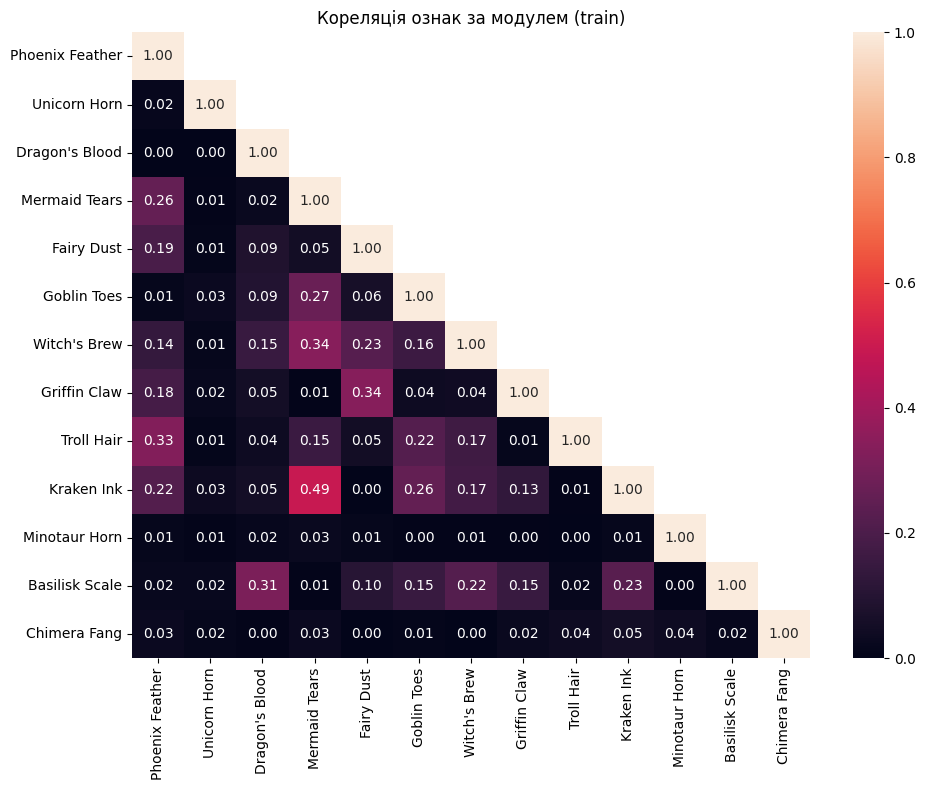

In [12]:
mtx = X_train.corr().abs()

mask = np.triu(np.ones_like(mtx, dtype=bool), k=1)

plt.figure(figsize=(10, 8))
sns.heatmap(mtx, mask=mask, annot=True, fmt='.2f',
            cmap='rocket', vmin=0, vmax=1)
plt.title('Кореляція ознак за модулем (train)')
plt.tight_layout()
plt.show()

In [13]:
corr_pr = pd.concat([X_train, y_train], axis=1).corr().abs()['Cured'].drop('Cured')
corr_pr.sort_values()

,Cured
Mermaid Tears,0.002419
Unicorn Horn,0.004218
Griffin Claw,0.005871
Dragon's Blood,0.010119
Fairy Dust,0.014223
Phoenix Feather,0.020527
Minotaur Horn,0.021922
Kraken Ink,0.026598
Basilisk Scale,0.042277
Chimera Fang,0.047292


Найвищу кореляцію з цільовою змінною мають ознаки Troll Hair (близько 0.4888) та Witch's Brew (близько 0.2470). Вони демонструють найпомітніший лінійний зв'язок із результатом одужання.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [14]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [15]:
model = LogisticRegression()

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 89.32%

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

In [20]:
conf = confusion_matrix(y_test, y_pred)
conf


array([[207,  24],
       [ 26, 211]])

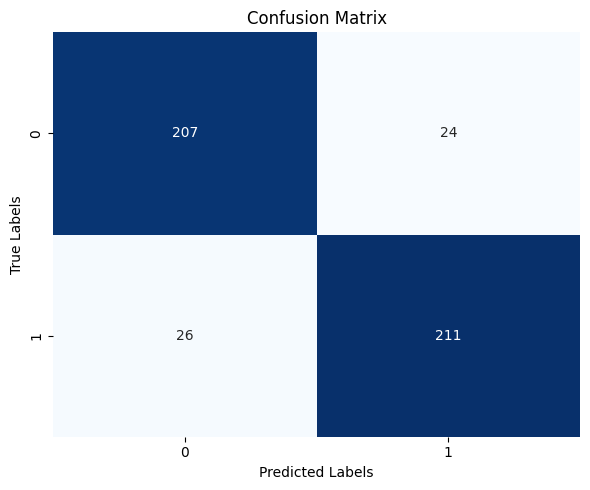

In [21]:
plt.figure(figsize=(6, 5))
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=True, yticklabels=True)

# Додаємо заголовки
plt.title("Confusion Matrix")
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')

# Показуємо графік
plt.tight_layout()
plt.show()

In [22]:
# Створюємо датафрейм
comparison_df = pd.DataFrame({
    "True Class": y_test.values,
    "Predicted Class": y_pred
})

# Вибираємо 10 випадкових зразків
random_samples = comparison_df.sample(10, random_state=42)

print("\n10 випадкових зразків:")
print(random_samples)


10 випадкових зразків:
     True Class  Predicted Class
55            0                1
63            0                0
33            1                0
297           1                1
72            1                1
228           0                0
209           1                1
9             1                1
428           0                0
231           1                1


Яких помилок більше?Хибнонегативних помилок (False Negatives — FN): 26 (модель передбачила клас 0, хоча справжнім був клас 1).   Хибнопозитивних помилок (False Positives — FP): 24 (модель передбачила клас 1, хоча справжнім був клас 0).   Кількість хибнонегативних помилок ($26$) трохи перевищує кількість хибнопозитивних ($24$), проте загалом помилки розподілені досить симетрично. Загальна кількість правильних передбачень ($207 + 211 = 418$) суттєво переважає кількість помилок ($24 + 26 = 50$).   Чи достатньо однієї метрики Accuracy?Ні, однієї метрики Accuracy недостатньо.Хоча в цьому випадку класи збалансовані і загальна точність (Accuracy) буде високою, спиратися виключно на неї не варто.   Для повноцінної оцінки якості моделі обов'язково використовують додаткові метрики (Precision, Recall, F1-score). Вони допомагають побачити баланс між повнотою та точністю для кожного класу окремо та зрозуміти ціну кожного типу помилок (наприклад, пропуск пацієнта проти хибної тривоги).

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [23]:
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],  # параметр регуляризації
    'solver': ['lbfgs', 'liblinear'],  # алгоритми оптимізації
    'max_iter': [100, 200, 300]  # кількість ітерацій
}

# Для RandomizedSearchCV
param_dist = {
    'solver': ['liblinear', 'lbfgs'],
    'C': np.logspace(-2, 2, 10),
    'max_iter': [100, 500]
}

In [24]:
grid = GridSearchCV(
    LogisticRegression(),
    param_grid,
    cv=3,
    n_jobs=-1,
    scoring='accuracy',
    verbose=1
)
grid.fit(X_train_scaled, y_train)

print("GridSearchCV найкращі параметри:")
print(grid.best_params_)

Fitting 3 folds for each of 30 candidates, totalling 90 fits
GridSearchCV найкращі параметри:
{'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}


In [25]:
random_search = RandomizedSearchCV(
    LogisticRegression(),
    param_distributions=param_dist,
    n_iter=20,
    cv=3,
    n_jobs=-1,
    scoring='accuracy',
    verbose=1,
    random_state=42
)
random_search.fit(X_train_scaled, y_train)

print("RandomizedSearchCV найкращі параметри:")
print(random_search.best_params_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
RandomizedSearchCV найкращі параметри:
{'solver': 'lbfgs', 'max_iter': 100, 'C': np.float64(100.0)}


In [26]:
best_model = random_search.best_estimator_
best_model.fit(X_train_scaled, y_train)

y_pred = best_model.predict(X_test_scaled)

print(f"\nAccuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 89.32%

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



Який метод пошуку обрав які параметри?Для GridSearchCV найкращі параметри: {'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}.   Для RandomizedSearchCV найкращі параметри: {'solver': 'lbfgs', 'max_iter': 100, 'C': np.float64(100.0)} (де $C = 100$).
Чи покращилась якість порівняно з базовою моделлю?Так, якість покращилась.Завдяки підбору гіперпараметрів (регуляризації $C$ та оптимізатору) точність (Accuracy) моделі на тестовому наборі даних досягла 89.32%.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [27]:
models = {
    'Логістична регресія': best_model,
    'SVM': SVC(),
    'Дерево рішень': DecisionTreeClassifier(random_state=42)
}

results = []
for name, clf in models.items():
    clf.fit(X_train_scaled, y_train)
    prediction = clf.predict(X_test_scaled)
    results.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, prediction),
        'F1-score': f1_score(y_test, prediction)
    })

results_df = pd.DataFrame(results).sort_values('Accuracy', ascending=False)
print(results_df.to_string(index=False))
print('\nНайкраща модель за Accuracy:', results_df.iloc[0]['Модель'])

             Модель  Accuracy  F1-score
                SVM  0.959402  0.960000
Логістична регресія  0.893162  0.894068
      Дерево рішень  0.865385  0.865672

Найкраща модель за Accuracy: SVM


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

**Ваші висновки:**  
Під час виконання лабораторної роботи було проведено аналіз датасету *Cure the Princess*, який містить 2338 спостережень і 13 ознак магічних інгредієнтів. Пропущені значення у даних відсутні, а цільова змінна `Cured` має два класи, представлені приблизно порівну.

Дослідження викидів на навчальній вибірці за правилом 1,5 IQR показало, що найбільша кількість потенційних викидів спостерігається в ознаці `Witch's Brew` — 33. Було визначено, що найвищу кореляцію з цільовою змінною мають `Troll Hair` (приблизно 0,4888) та `Witch's Brew` (приблизно 0,2470). Перед навчанням моделей ознаки було стандартизовано.

Базова модель логістичної регресії досягла точності **89,32%** на тестовій вибірці. Підбір гіперпараметрів за допомогою `GridSearchCV` та `RandomizedSearchCV` не призвів до покращення точності порівняно з базовою моделлю, оскільки результат залишився на рівні 89,32%.

Під час порівняння трьох моделей найкращий результат показав метод опорних векторів (`SVM`), точність якого становила **95,94%**, а F1-score — **0,96**. Логістична регресія досягла Accuracy 89,32% і F1-score 0,8941, тоді як дерево рішень показало відповідно 86,54% та 0,8657.

Отже, за результатами експерименту найкращою моделлю для класифікації виявився SVM, оскільки він продемонстрував найвищі значення Accuracy та F1-score на тестовій вибірці. Поставленої мети лабораторної роботи досягнуто: побудовано та оцінено моделі бінарної класифікації, виконано підбір гіперпараметрів і порівняно ефективність різних алгоритмів машинного навчання.

---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.